In [4]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'


In [6]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.tail(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
635,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2213,None,37883,None,None,0
636,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,1588,None,5676,None,None,0


In [7]:
milk.columns

Index(['Classification', 'Year', 'Period', 'Period Desc.', 'Aggregate Level',
       'Is Leaf Code', 'Trade Flow Code', 'Trade Flow', 'Reporter Code',
       'Reporter', 'Reporter ISO', 'Partner Code', 'Partner', 'Partner ISO',
       '2nd Partner Code', '2nd Partner', '2nd Partner ISO',
       'Customs Proc. Code', 'Customs', 'Mode of Transport Code',
       'Mode of Transport', 'Commodity Code', 'Commodity', 'Qty Unit Code',
       'Qty Unit', 'Qty', 'Alt Qty Unit Code', 'Alt Qty Unit', 'Alt Qty',
       'Netweight (kg)', 'Gross weight (kg)', 'Trade Value (US$)',
       'CIF Trade Value (US$)', 'FOB Trade Value (US$)', 'Flag'],
      dtype='str')

In [8]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed' 
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


In [10]:
milk = milk[milk[PARTNER] != 'World'].copy()
milk.head()


,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


PROJECT QUESTIONS 1

In [13]:
grouped = milk.groupby([FLOW])
trade_total=grouped[VALUE].sum()
trade_total


Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

In [ ]:
# Trade balance
total_exports=trade_total['Exports']
total_imports=trade_total['Imports']

trade_balance =total_exports-total_imports

print("Total exports:", total_exports)
print("Total imports:", total_imports)
print("Total balance:", trade_balance)

Total exports: 265029661
Total imports: 156483978
Total balance: 108545683


Question 2

In [16]:
imports = milk[milk[FLOW] == 'Imports'].copy()
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()


The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

In [19]:
totalImports=grouped[VALUE].sum()
totalImports=totalImports.sort_values(ascending=False)
totalImports.head()

Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

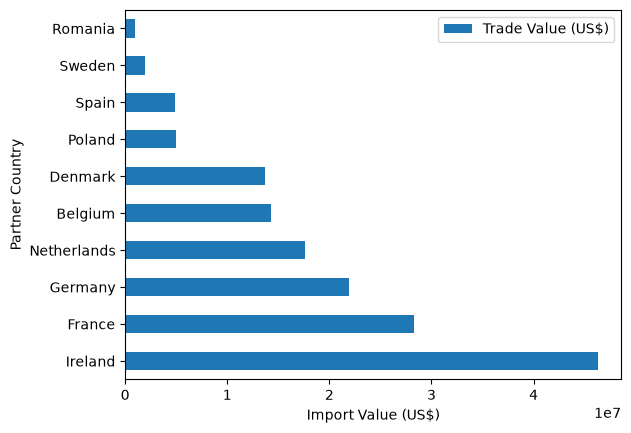

In [20]:
totalImports.head(10).plot(kind='barh')
plt.xlabel('Import Value (US$)')
plt.ylabel('Partner Country')
plt.legend()
plt.show()

In [21]:
#export
exports = milk[milk[FLOW] == 'Exports'].copy()
grouped=exports.groupby(PARTNER)

In [22]:
totalExportss=grouped[VALUE].sum()
totalExports=totalImports.sort_values(ascending=False)
totalExports.head()

Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

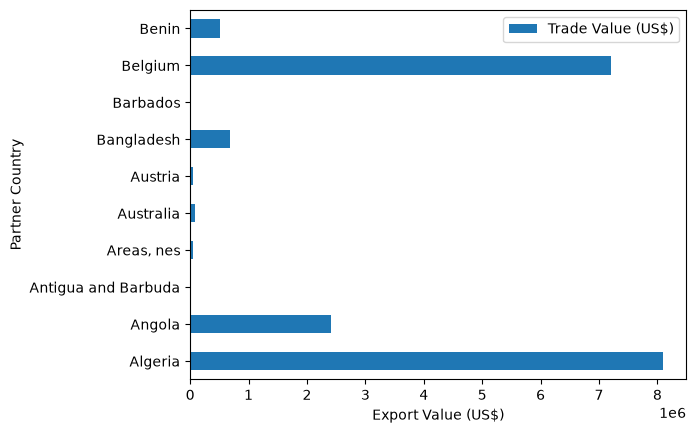

In [23]:
totalExportss.head(10).plot(kind='barh')
plt.xlabel('Export Value (US$)')
plt.ylabel('Partner Country')
plt.legend()
plt.show()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

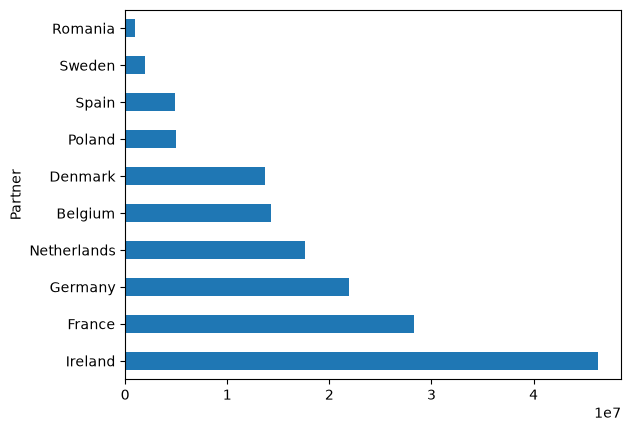

In [24]:
totalImports.head(10).plot(kind='barh')
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

Question 3

In [25]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]


,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


In [26]:
regular.groupby(PARTNER).ngroups

17

In [27]:
regular[VALUE].sum() / exports[VALUE].sum()


np.float64(0.7583526396315317)

4

In [28]:
countries =pd.pivot_table(milk, index=[PARTNER], columns=[FLOW], 
                        values=VALUE, aggfunc=sum)
countries.head()


Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


In [29]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


MY ANALYSIS

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


In [33]:
LOCATION = 'comtrade_uk_milk_2024.csv'
LOCATION='comtrade_uk_milk_2024.csv'
df=pd.read_csv(LOCATION)
print(df['flowCode'].value_counts())

flowCode
Export    909
Import    412
Name: count, dtype: int64


In [34]:
df.head()

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
C,M,20240101,2024,1,202401,826,GBR,United Kingdom,M,Import,...,False,0,False,1.409862e+07,NaN,1.409862e+07,0,False,True,NaN
C,M,20240101,2024,1,202401,826,GBR,United Kingdom,M,Import,...,False,0,False,1.713380e+05,NaN,1.713380e+05,0,False,True,NaN
C,M,20240101,2024,1,202401,826,GBR,United Kingdom,M,Import,...,False,0,False,1.315187e+05,NaN,1.315187e+05,0,False,True,NaN
C,M,20240101,2024,1,202401,826,GBR,United Kingdom,M,Import,...,False,0,False,7.965673e+05,NaN,7.965673e+05,0,False,True,NaN
C,M,20240101,2024,1,202401,826,GBR,United Kingdom,M,Import,...,False,0,False,1.096952e+06,NaN,1.096952e+06,0,False,True,NaN


In [40]:
print(df.columns.tolist())

['typeCode', 'freqCode', 'refPeriodId', 'refYear', 'refMonth', 'period', 'reporterCode', 'reporterISO', 'reporterDesc', 'flowCode', 'flowDesc', 'partnerCode', 'partnerISO', 'partnerDesc', 'partner2Code', 'partner2ISO', 'partner2Desc', 'classificationCode', 'classificationSearchCode', 'isOriginalClassification', 'cmdCode', 'cmdDesc', 'aggrLevel', 'isLeaf', 'customsCode', 'customsDesc', 'mosCode', 'motCode', 'motDesc', 'qtyUnitCode', 'qtyUnitAbbr', 'qty', 'isQtyEstimated', 'altQtyUnitCode', 'altQtyUnitAbbr', 'altQty', 'isAltQtyEstimated', 'netWgt', 'isNetWgtEstimated', 'grossWgt', 'isGrossWgtEstimated', 'cifvalue', 'fobvalue', 'primaryValue', 'legacyEstimationFlag', 'isReported', 'isAggregate']


In [42]:
trade_totals=df.groupby('flowCode')[
    'primaryValue'
].sum()
trade_totals

flowCode
Export    150
Import      6
Name: primaryValue, dtype: int64

In [43]:
total_exports=trade_totals['Export']
total_imports=trade_totals['Import']
balance= total_exports-total_imports

print('Export:', total_exports)
print('Import:', total_imports)
print('Balance:', balance)

Export: 150
Import: 6
Balance: 144


In [45]:
imports=df[df['flowCode']== 'Import']
import_partners=(imports.groupby('partnerDesc')['primaryValue'].sum().sort_values(ascending=False)
)
import_partners.head()

partnerDesc
0    6
Name: primaryValue, dtype: int64

In [47]:
exports=df[df['flowCode']== 'Export']
export_partners=(exports.groupby('partnerDesc')['primaryValue'].sum().sort_values(ascending=False)
)
export_partners.head()

partnerDesc
0    150
Name: primaryValue, dtype: int64

In [52]:
monthly_count=exports.groupby('partnerDesc')['refMonth'].nunique()
regular_partners_list=monthly_count[monthly_count==12].index

In [53]:
regular_exports=exports[exports['partnerDesc'].isin(regular_partners_list)]

In [59]:
regular_value=regular_exports['primaryValue'].sum()
total_export_value=exports['primaryValue'].sum()


In [60]:
print(len(regular_partners_list))

1


In [65]:
df_clean=df[df['partnerDesc'].isin(['World', '0', 0])].copy()
df['partnerDesc']=df['partnerDesc'].astype(str)
df_clean=df[df['partnerDesc'].isin([ '0', 'World'])].copy()

In [66]:
trade_pivot=pd.pivot_table(df,
                           index='partnerDesc',
                           columns='flowCode',
                           values='primaryValue',
                           aggfunc='sum',
                           fill_value=0)
trade_pivot.head()

flowCode,Export,Import
partnerDesc,,
0,150,6


In [67]:
bidirectional=trade_pivot.dropna()
bidirectional

flowCode,Export,Import
partnerDesc,,
0,150,6


DATA VISUALIZATION

In [1]:
import numpy as np
import pandas as pd 
from numpy.random import random
from scipy import stats
import matplotlib as npl
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [5]:
df=pd.read_csv('comtrade_nigeria_monthly_2023.csv')
print(df.columns)

Index(['typeCode', 'freqCode', 'refPeriodId', 'refYear', 'refMonth', 'period',
       'reporterCode', 'reporterISO', 'reporterDesc', 'flowCode', 'flowDesc',
       'partnerCode', 'partnerISO', 'partnerDesc', 'partner2Code',
       'partner2ISO', 'partner2Desc', 'classificationCode',
       'classificationSearchCode', 'isOriginalClassification', 'cmdCode',
       'cmdDesc', 'aggrLevel', 'isLeaf', 'customsCode', 'customsDesc',
       'mosCode', 'motCode', 'motDesc', 'qtyUnitCode', 'qtyUnitAbbr', 'qty',
       'isQtyEstimated', 'altQtyUnitCode', 'altQtyUnitAbbr', 'altQty',
       'isAltQtyEstimated', 'netWgt', 'isNetWgtEstimated', 'grossWgt',
       'isGrossWgtEstimated', 'cifvalue', 'fobvalue', 'primaryValue',
       'legacyEstimationFlag', 'isReported', 'isAggregate'],
      dtype='str')


In [15]:
print(df['primaryValue'].head(10))
print(df['primaryValue'].describe())
print(df['cifvalue'].head(10))
print(df['fobvalue'].head(10))
print(df['cmdDesc'].unique()[:5])

C    4
C    0
C    0
C    0
C    0
C    0
C    0
C    0
C    0
C    0
Name: primaryValue, dtype: int64
count    2672.000000
mean        0.932635
std         1.691686
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         4.000000
Name: primaryValue, dtype: float64
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
C   NaN
Name: cifvalue, dtype: float64
C    5.027250e+09
C    5.196588e+03
C    3.007572e+04
C    4.407545e+04
C    3.282966e+05
C    3.229400e+03
C    3.750196e+04
C    2.316269e+05
C    1.055047e+06
C    7.396456e+05
Name: fobvalue, dtype: float64
[0]


In [18]:
df['fobvalue']=pd.to_numeric(df['fobvalue'], errors='coerce')
df['cifvalue']=pd.to_numeric(df['cifvalue'], errors='coerce')
df_clean=df.dropna(subset=['fobvalue'])
df_clean=df[df['fobvalue']>0]


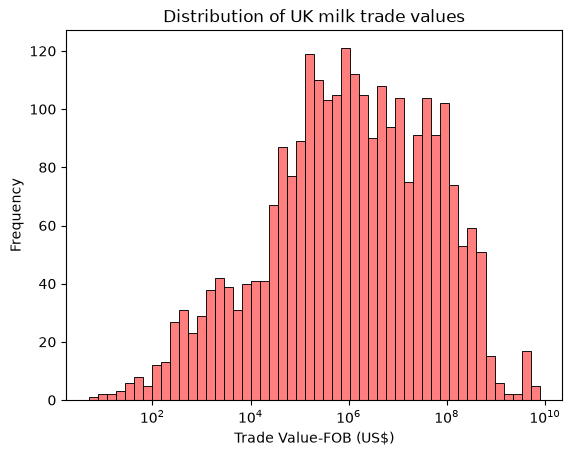

In [19]:
sns.histplot(data=df,
             x='fobvalue',
             alpha=0.5,
             color='r',
             bins=50,
             log_scale=True
)
plt.title('Distribution of UK milk trade values')
plt.xlabel('Trade Value-FOB (US$)')
plt.ylabel('Frequency')
plt.show()


The distribution shows the milk trade values on a log scale. It shows most trades fall between 10^4 to 10^8 (10kto100MUS), with the peak around $10^6 ($1M), indicating a typical log_normal distribution for trade data.

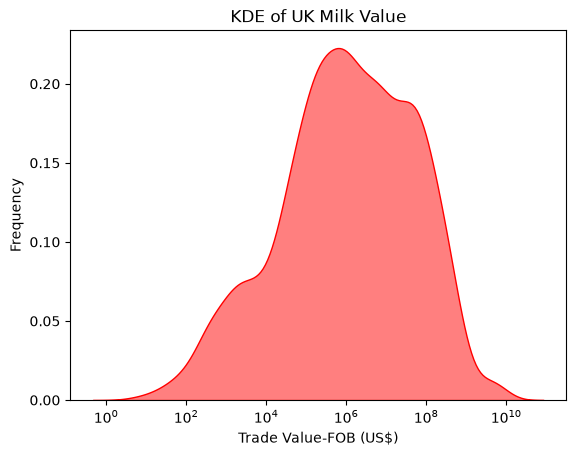

In [ ]:
sns.kdeplot(data=df,
             x='fobvalue',
             alpha=0.5,
             color='r',
             fill=True,
             log_scale=True
)
plt.title('KDE of UK Milk Value')
plt.xlabel('Trade Value-FOB (US$)')
plt.ylabel('Frequency')
plt.show()


This KDE plot shows the probability of density of trade values on a log_scale. It comfirms a right_skewed,log_normal distribution with most trade values concentrated between $10^4 and $10^8, peaking around $10^6 ($1M). The smooth curve shows the most frequent trade value is approximately $1 million, with fewer very small and very large transactions.

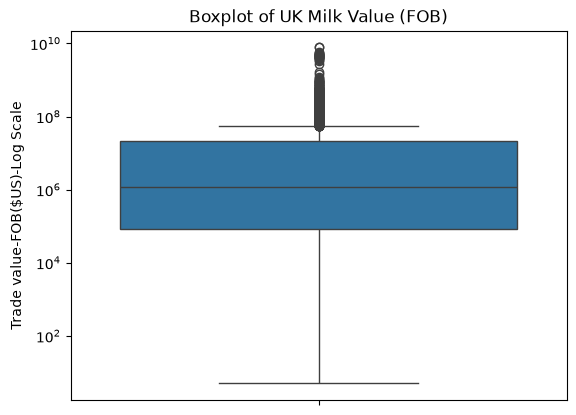

In [25]:
sns.boxplot(data=df_clean,
             y='fobvalue')
plt.title('Boxplot of UK Milk Value (FOB)')
plt.yscale('log')
plt.ylabel('Trade value-FOB($US)-Log Scale')
plt.show()

This boxplot shows distribution of FOB trade values on a log_scale. The median (middle line) is about $10^6 ($1M). The box shows 50% of trades fall between $10^5 and $10^7 ($100k-$100M). The dots at the top are outliers- a few very high value trades up to $10^10 ($10B).The long whisker at the bottom shows some vry small trades down to $10^0 ($1).

In [31]:
df['refMonth']=pd.to_numeric(df['refMonth'], errors='coerce')
monthly_flow=(df.groupby(['refMonth', 'flowCode'])
              ['fobvalue'].sum().unstack()
)
monthly_flow.head()

flowCode,Export,Import
refMonth,,
202301,9.918047e+09,1.005450e+10
202302,8.315689e+09,8.439692e+09
202303,9.913269e+09,9.561944e+09
202304,7.750122e+09,8.393058e+09
202305,8.170853e+09,1.145066e+10


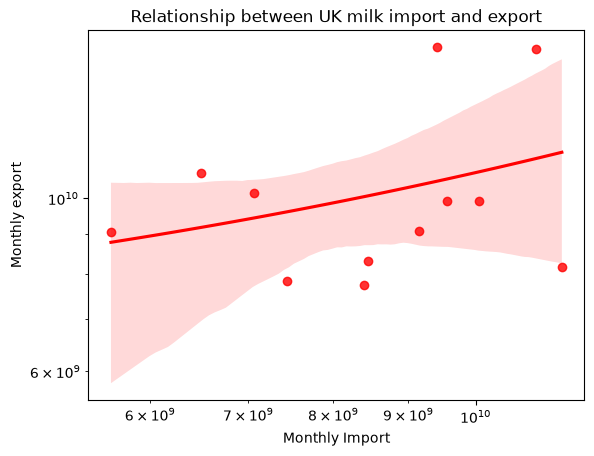

In [33]:
sns.regplot(data=monthly_flow,
             x='Import',
             y='Export',
             color='r',
            
)
plt.xscale('log')
plt.yscale('log')
plt.title('Relationship between UK milk import and export')
plt.xlabel('Monthly Import')
plt.ylabel('Monthly export')
plt.show()

The data was aggregated by month and trade flow (Import and Export) using groupby (['refMonth', 'flowCode]).sum(). The regression shows a weak positive relationship between monthly imports and exports. As monthly import increases, export values also show a slight increase, but the wide confidence interval(shaded area)and the scattered point indicate the relationship is not strong.Most monthly trade values cluster between $6B and $11B.

In [40]:
heatmap_data=pd.pivot_table(df,
                            index='period',
                            columns=['flowDesc'],
                            values='fobvalue',
                            aggfunc='sum'
)
heatmap_data.head()

flowDesc,0,4,8,12,16,20,24,28,31,32,...,834,842,854,858,860,862,882,887,894,899
period,,,,,,,,,,,,,,,,,,,,,
566,1.131066e+11,22379.318,70495.687,3697040.376,58943.106,1024324.674,5835861.265,239166.676,6544235.954,1.337680e+08,...,5.379297e+07,8.678482e+09,2.183871e+07,3.303069e+08,6122.376,1050507.882,5.039,2.350926e+07,924688.941,2.863975e+08


In [41]:
heatmap_data=(df.groupby(['refMonth', 'flowCode'])
              ['fobvalue'].sum().unstack()
)
heatmap_data.head(12)

flowCode,Export,Import
refMonth,,
202301,9.918047e+09,1.005450e+10
202302,8.315689e+09,8.439692e+09
202303,9.913269e+09,9.561944e+09
202304,7.750122e+09,8.393058e+09
202305,8.170853e+09,1.145066e+10
202306,9.043138e+09,5.640499e+09
202307,7.831511e+09,7.436726e+09
202308,9.086687e+09,9.146743e+09
202309,1.015095e+10,7.063903e+09


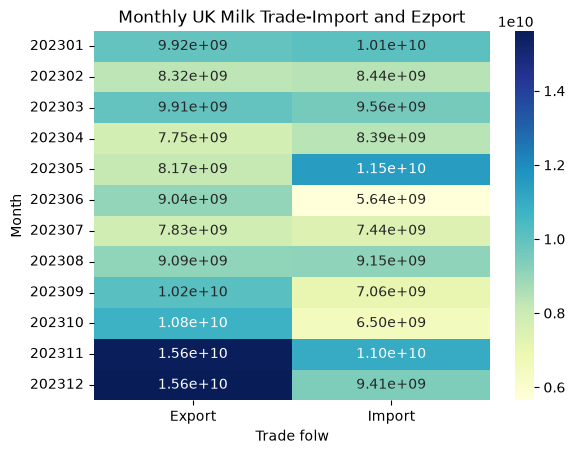

In [42]:
sns.heatmap(heatmap_data,
            annot=True,
            fmt='.2e',
            cmap='YlGnBu'
)
plt.title('Monthly UK Milk Trade-Import and Ezport')
plt.xlabel('Trade folw')
plt.ylabel('Month')
plt.show()


This heatmap was created after aggregating the data by month (period) and trade flow (flowDesc) using groupby().sum(). The aggregation sums total FOB value per month for each flow. Darker blue indicates higehr trade value. Exports  peaked in November and December2023 ($1.56*10^10) while impoerts peaked in May 2023 ($1.15*10^10). Tarde was consistently high throughout 2023, ranging between $5.6B and $15.6B per month for both flows, showing active two-way milk trade.

SQL PRACTICE

In [19]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(
    f"Practice ready: {len(TITLES)} tasks. Connected as:",
    q("SELECT CURRENT_USER AS u").u[0]
)

Practice ready: 5 tasks. Connected as: intern_readonly


1

In [20]:
SQL_01 = """
SELECT [Trade Flow] AS trade_flow,
CASE
    WHEN [Commodity Code]='0401'
THEN 'unprocessed'
    WHEN [Commodity Code]='0402'
THEN 'processed'
    END AS milk_type,
    COUNT(DISTINCT Partner) AS partners,

    ROUND(
         SUM([Trade Value (us$)])/1000000.0,
         2
    ) AS total_musd
FROM week09.comtrade_milk_uk_jan_jul_15
WHERE Partner <>'World'
GROUP BY
       [Trade Flow],
       CASE
          WHEN [Commodity Code]='0401'
THEN 'unprocessed'
          WHEN [Commodity Code]='0402'
THEN 'processed'
      END

    ORDER BY
       trade_flow ASC,
       milk_type ASC;  
"""
p.sql("s01", SQL_01)


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


✅ s01: correct!


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


2

In [21]:
SQL_02 = """
SELECT
    Period AS period,

    ROUND(
        SUM(
            CASE
                WHEN [Trade Flow] = 'Imports'
                THEN [Trade Value (US$)]
                ELSE 0
            END
        ) / 1000000.0,
        2
    ) AS imports_musd,

    ROUND(
        SUM(
            CASE
                WHEN [Trade Flow] = 'Exports'
                THEN [Trade Value (US$)]
                ELSE 0
            END
        ) / 1000000.0,
        2
    ) AS exports_musd,

    ROUND(
        (
            SUM(
                CASE
                    WHEN [Trade Flow] = 'Exports'
                    THEN [Trade Value (US$)]
                    ELSE 0
                END
            )
            -
            SUM(
                CASE
                    WHEN [Trade Flow] = 'Imports'
                    THEN [Trade Value (US$)]
                    ELSE 0
                END
            )
        ) / 1000000.0,
        2
    ) AS balance_musd

FROM week09.countrymilk

GROUP BY Period

ORDER BY Period ASC;
"""
p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


3

In [22]:
SQL_03 = """

WITH TradeQuarter AS (
    SELECT
        [Trade Flow] AS trade_flow,

        (Period % 100 + 2) / 3 AS quarter_num,

        [Trade Value (US$)] AS trade_value

    FROM week09.countrymilk
)

SELECT
    trade_flow,

    CASE
        WHEN GROUPING(quarter_num) = 1
            THEN 'Year'
        ELSE 'Q' + CAST(quarter_num AS VARCHAR(1))
    END AS quarter,

    ROUND(
        SUM(trade_value) / 1000000.0,
        2
    ) AS total_musd

FROM TradeQuarter

GROUP BY GROUPING SETS (
    (trade_flow, quarter_num),
    (trade_flow)
)

ORDER BY
    trade_flow ASC,

    CASE
        WHEN GROUPING(quarter_num) = 1 THEN 5
        ELSE quarter_num
    END ASC;
    """
p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


4

In [23]:
SQL_04 = """
WITH PartnerTotals AS (
    SELECT
        [Trade Flow] AS trade_flow,
        Partner AS partner,
        SUM([Trade Value (US$)]) AS total_value

    FROM week09.countrymilk

    GROUP BY
        [Trade Flow],
        Partner
),

RankedPartners AS (
    SELECT
        trade_flow,
        partner,
        total_value,

        ROW_NUMBER() OVER (
            PARTITION BY trade_flow
            ORDER BY total_value DESC, partner ASC
        ) AS partner_rank,

        SUM(total_value) OVER (
            PARTITION BY trade_flow
        ) AS flow_total

    FROM PartnerTotals
)

SELECT
    trade_flow,
    partner_rank AS [rank],
    partner,

    ROUND(
        total_value / 1000000.0,
        2
    ) AS total_musd,

    ROUND(
        total_value * 100.0 / flow_total,
        1
    ) AS share_pct

FROM RankedPartners

WHERE partner_rank <= 3

ORDER BY
    trade_flow ASC,
    partner_rank ASC;
"""
p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


5

In [24]:
SQL_05 = """
WITH ExportRows AS (
    SELECT
        Period AS period,
        Partner AS partner,
        [Trade Value (US$)] AS trade_value

    FROM week09.comtrade_milk_uk_jan_jul_15

    WHERE
        [Trade Flow] = 'Exports'
        AND Partner <> 'World'
),

Top5 AS (
    SELECT TOP 5
        partner

    FROM ExportRows

    GROUP BY partner

    ORDER BY
        SUM(trade_value) DESC,
        partner ASC
),

MonthlyGroups AS (
    SELECT
        e.period,

        CASE
            WHEN t.partner IS NOT NULL
                THEN e.partner
            ELSE 'Other'
        END AS partner_group,

        SUM(e.trade_value) AS group_value

    FROM ExportRows AS e

    LEFT JOIN Top5 AS t
        ON e.partner = t.partner

    GROUP BY
        e.period,

        CASE
            WHEN t.partner IS NOT NULL
                THEN e.partner
            ELSE 'Other'
        END
)

SELECT
    period,
    partner_group,

    ROUND(
        group_value / 1000000.0,
        2
    ) AS exports_musd,

    ROUND(
        group_value * 100.0
        /
        SUM(group_value) OVER (
            PARTITION BY period
        ),
        1
    ) AS share_pct

FROM MonthlyGroups

ORDER BY
    period ASC,

    CASE
        WHEN partner_group = 'Other' THEN 1
        ELSE 0
    END ASC,

    partner_group ASC;
"""
p.sql("s05", SQL_05)

,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


✅ s05: correct!


,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


In [27]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,✅
